<a href="https://colab.research.google.com/github/PaoloniCoder/MozartAI/blob/m1-dataset-vocabolario/notebooks/Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MozartAI · M1 · Modello base: addestramento e valutazione

Un modello CRNN + CTC che legge una riga di pentagramma (immagine) e scrive la
sequenza di simboli musicali, con altezza e durata delle note.

- Dataset: PrIMuS, etichette in codifica semantic
- Modello: convoluzioni + LSTM bidirezionale, loss CTC
- Metrica: SER (Symbol Error Rate) sulla validazione

Runtime richiesto: T4 GPU. Eseguire le celle in ordine.

## 3. Esempi e vocabolario
Ogni simbolo diverso diventa un numero. Lo 0 è riservato al blank della CTC.
Il vocabolario è costruito su tutto il dataset.

In [3]:
SEED = 42
IMG_H = 128            # altezza a cui portiamo tutte le immagini
BATCH = 16
EPOCHS = 20
LR = 1e-3
NUM_SAMPLES = 20000    # quanti esempi usare (il dataset ne ha 87.678)
VAL_SIZE = 1000
LABEL_EXT = '.semantic'   # '.semantic' = note con altezza e durata (serve per il MIDI)
CACHE = True              # immagini in RAM: veloce con 20-40k esempi. Se alzi NUM_SAMPLES oltre 40000, metti False

ARCHIVE = '/content/drive/MyDrive/MozartAI/data/primus.tgz'      # archivio già scaricato
VOCAB_PATH = '/content/drive/MyDrive/MozartAI/vocab_semantic.json'
MARTINO_VOCAB = '/content/drive/MyDrive/spartiti/m1/vocab.json'  # vocabolario dell'Issue 1 (se esiste)
CKPT_DIR = '/content/drive/MyDrive/MozartAI/checkpoints_v2'

import os, json, random, time, math
from pathlib import Path
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Sampler
from google.colab import drive

drive.mount('/content/drive')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'      # calcolo a 16 bit: più veloce sulla T4
os.makedirs(CKPT_DIR, exist_ok=True)
print('Dispositivo:', DEVICE)

Mounted at /content/drive
Dispositivo: cuda


## 4. Dataset e DataLoader
Immagini portate a 128 px di altezza, con padding bianco a destra per creare i batch.
I batch raggruppano immagini di larghezza simile per ridurre il padding.
Controlla anche che ogni immagine abbia abbastanza "fettine" per scrivere la sua sequenza.

In [4]:
ROOT = Path('/content/primus')
if not (ROOT / '.ok').exists():
    ROOT.mkdir(parents=True, exist_ok=True)
    !tar -xzf "{ARCHIVE}" -C "{ROOT}" --exclude='._*' --wildcards '*.png' '*.semantic'
    (ROOT / '.ok').touch()
print('Pronto.')

Pronto.


## 5. Modello (CRNN)
Le convoluzioni estraggono le caratteristiche dall'immagine, la LSTM le legge da sinistra
a destra, il livello finale dà un punteggio per ogni simbolo (più il blank).

In [5]:
def find_samples(root):
    out = []
    for d, _, files in os.walk(root):
        lab = [f for f in files if f.endswith(LABEL_EXT) and not f.startswith('._')]
        img = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('._')]
        if lab and img:
            img.sort(key=lambda f: 'distorted' not in f)   # se esiste, preferisco la versione "foto"
            out.append((os.path.join(d, img[0]), os.path.join(d, lab[0])))
    return sorted(out)

all_samples = find_samples(ROOT)
all_tokens = [open(l, encoding='utf-8').read().split() for _, l in tqdm(all_samples, desc='Leggo etichette')]
print('Esempi nel dataset:', len(all_samples))

# Vocabolario costruito su TUTTO il dataset (così non troveremo mai simboli sconosciuti). 0 = blank CTC.
vocab = sorted({t for toks in all_tokens for t in toks})
tok2id = {t: i + 1 for i, t in enumerate(vocab)}
id2tok = {i: t for t, i in tok2id.items()}
NUM_CLASSES = len(vocab) + 1
json.dump(tok2id, open(VOCAB_PATH, 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
print('Simboli diversi:', len(vocab), '| sequenza più lunga:', max(map(len, all_tokens)))
if os.path.exists(MARTINO_VOCAB):
    print('Uguale al vocabolario di Martino:', json.load(open(MARTINO_VOCAB, encoding='utf-8')) == tok2id)

idx = list(range(len(all_samples)))
random.Random(SEED).shuffle(idx)
idx = idx[:NUM_SAMPLES]
items = [(all_samples[i][0], [tok2id[t] for t in all_tokens[i]]) for i in idx]
val_items, train_items = items[:VAL_SIZE], items[VAL_SIZE:]
print('Train:', len(train_items), '| Validazione:', len(val_items))

Leggo etichette:   0%|          | 0/87678 [00:00<?, ?it/s]

Esempi nel dataset: 87678
Simboli diversi: 1781 | sequenza più lunga: 58
Uguale al vocabolario di Martino: True
Train: 19000 | Validazione: 1000


## 6. Addestramento
Loss CTC, ottimizzatore AdamW. A ogni epoca salva un checkpoint su Drive, e se Colab
si disconnette l'addestramento riparte dall'ultima epoca. Contiene anche la decodifica
greedy e la distanza di edit usate per il SER.

In [6]:
class OMRDataset(Dataset):
    def __init__(self, items, cache):
        self.items = items
        self.widths = []
        for p, _ in items:                      # leggo solo l'intestazione: veloce
            with Image.open(p) as im:
                w, h = im.size
            self.widths.append(max(8, round(w * IMG_H / h)))
        self.images = None
        if cache:
            self.images = [self.load(p, w) for (p, _), w in tqdm(zip(items, self.widths), total=len(items), desc='Carico immagini')]

    @staticmethod
    def load(path, w):
        with Image.open(path) as im:
            im = im.convert('L').resize((w, IMG_H), Image.Resampling.BILINEAR)
            return np.asarray(im, dtype=np.uint8)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, ids = self.items[i]
        arr = self.images[i] if self.images is not None else self.load(path, self.widths[i])
        x = torch.from_numpy(arr).float().div_(255).unsqueeze(0)     # 1 = sfondo bianco
        return x, torch.tensor(ids, dtype=torch.long), self.widths[i]

def collate(batch):
    xs, ys, ws = zip(*batch)
    x = torch.ones(len(xs), 1, IMG_H, max(ws))                       # padding bianco
    for i, im in enumerate(xs):
        x[i, :, :, :im.shape[2]] = im
    return x, torch.cat(ys), torch.tensor([len(y) for y in ys]), torch.tensor(ws)

class BucketSampler(Sampler):
    """Mette nello stesso batch immagini di larghezza simile: meno padding, addestramento più veloce."""
    def __init__(self, widths, bs, shuffle, chunk=50):
        self.widths, self.bs, self.shuffle, self.chunk = widths, bs, shuffle, chunk
    def __iter__(self):
        idx = list(range(len(self.widths)))
        if self.shuffle:
            random.shuffle(idx)
        size, batches = self.bs * self.chunk, []
        for i in range(0, len(idx), size):
            part = sorted(idx[i:i + size], key=lambda j: self.widths[j])
            batches += [part[k:k + self.bs] for k in range(0, len(part), self.bs)]
        if self.shuffle:
            random.shuffle(batches)
        yield from batches
    def __len__(self):
        return math.ceil(len(self.widths) / self.bs)

train_ds, val_ds = OMRDataset(train_items, CACHE), OMRDataset(val_items, CACHE)
nw = 0 if CACHE else 2
train_loader = DataLoader(train_ds, batch_sampler=BucketSampler(train_ds.widths, BATCH, True), collate_fn=collate, num_workers=nw, pin_memory=True)
val_loader = DataLoader(val_ds, batch_sampler=BucketSampler(val_ds.widths, BATCH, False), collate_fn=collate, num_workers=nw, pin_memory=True)

# Controllo CTC (una volta sola): ogni immagine deve dare abbastanza "fettine" per scrivere la sua sequenza
def min_steps(ids):
    return len(ids) + sum(a == b for a, b in zip(ids, ids[1:]))
bad = [i for ds in (train_ds, val_ds) for i, (_, ids) in enumerate(ds.items) if ds.widths[i] // 4 < min_steps(ids)]
print('Esempi non compatibili con CTC:', len(bad))

Carico immagini:   0%|          | 0/19000 [00:00<?, ?it/s]

Carico immagini:   0%|          | 0/1000 [00:00<?, ?it/s]

Esempi non compatibili con CTC: 0


## 7. Test delle funzioni
Verifica con sequenze inventate che la decodifica greedy e la distanza di edit
diano i risultati attesi.

SER sulla validazione: 0.0085  (204 errori su 23920 simboli)
Sequenze perfette: 870 su 1000

===== MIGLIORE: 0 errori su 4 simboli =====


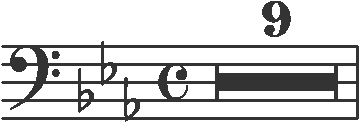

GIUSTO : ['clef-F4', 'keySignature-EbM', 'timeSignature-C', 'multirest-9']
MODELLO: ['clef-F4', 'keySignature-EbM', 'timeSignature-C', 'multirest-9']

===== MEDIO: 0 errori su 24 simboli =====


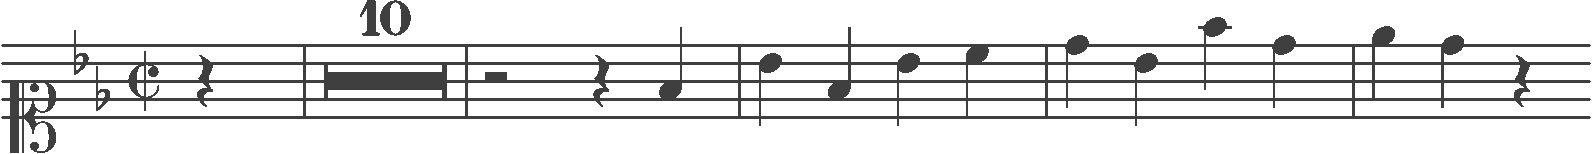

GIUSTO : ['clef-C1', 'keySignature-BbM', 'timeSignature-C/', 'rest-quarter', 'barline', 'multirest-10', 'barline', 'rest-half', 'rest-quarter', 'note-F4_quarter', 'barline', 'note-Bb4_quarter', 'note-F4_quarter', 'note-Bb4_quarter', 'note-C5_quarter', 'barline', 'note-D5_quarter', 'note-Bb4_quarter', 'note-F5_quarter', 'note-D5_quarter', 'barline', 'note-Eb5_quarter', 'note-D5_quarter', 'rest-quarter']
MODELLO: ['clef-C1', 'keySignature-BbM', 'timeSignature-C/', 'rest-quarter', 'barline', 'multirest-10', 'barline', 'rest-half', 'rest-quarter', 'note-F4_quarter', 'barline', 'note-Bb4_quarter', 'note-F4_quarter', 'note-Bb4_quarter', 'note-C5_quarter', 'barline', 'note-D5_quarter', 'note-Bb4_quarter', 'note-F5_quarter', 'note-D5_quarter', 'barline', 'note-Eb5_quarter', 'note-D5_quarter', 'rest-quarter']

===== PEGGIORE: 16 errori su 31 simboli =====


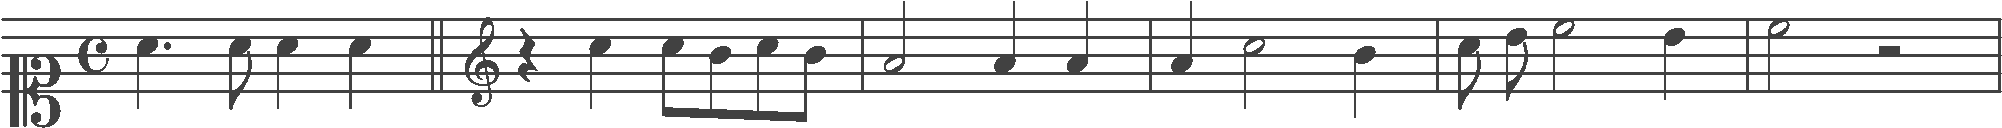

GIUSTO : ['clef-C1', 'timeSignature-C', 'note-A4_quarter.', 'note-A4_eighth', 'note-A4_quarter', 'note-A4_quarter', 'barline', 'clef-G2', 'rest-quarter', 'note-C5_quarter', 'note-C5_eighth', 'note-B4_eighth', 'note-C5_eighth', 'note-B4_eighth', 'barline', 'note-A4_half', 'note-A4_quarter', 'note-A4_quarter', 'barline', 'note-A4_quarter', 'note-C5_half', 'note-B4_quarter', 'barline', 'note-C5_eighth', 'note-D5_eighth', 'note-E5_half', 'note-D5_quarter', 'barline', 'note-E5_half', 'rest-half', 'barline']
MODELLO: ['clef-C1', 'timeSignature-C', 'note-A4_quarter.', 'note-A4_eighth', 'note-A4_quarter', 'note-A4_quarter', 'barline', 'clef-G2', 'rest-quarter', 'note-A4_quarter', 'note-A4_eighth', 'note-G4_eighth', 'note-A4_eighth', 'note-G4_eighth', 'barline', 'note-F4_half', 'note-F4_quarter', 'note-F4_quarter', 'barline', 'note-F4_quarter', 'note-A4_half', 'note-G4_quarter', 'barline', 'note-A4_eighth', 'note-B4_eighth', 'note-C5_half', 'note-B4_quarter', 'barline', 'note-C5_half', 'rest-ha

In [11]:
from IPython.display import display

ck = torch.load(best, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck['model'])
model.eval()

risultati = []
for idxs in BucketSampler(val_ds.widths, BATCH, False):
    x, y, yl, w = collate([val_ds[i] for i in idxs])
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        logits = model(x.to(DEVICE))
    logits = logits.float().cpu()
    for i, r, riga, T in zip(idxs, torch.split(y, yl.tolist()), logits, (w // 4).tolist()):
        pred = greedy(riga, T)
        ref = r.tolist()
        risultati.append((i, edit_distance(pred, ref), len(ref), pred, ref))

errori_tot = sum(r[1] for r in risultati)
simboli_tot = sum(r[2] for r in risultati)
perfette = sum(1 for r in risultati if r[1] == 0)
print(f"SER sulla validazione: {errori_tot / simboli_tot:.4f}  ({errori_tot} errori su {simboli_tot} simboli)")
print(f"Sequenze perfette: {perfette} su {len(risultati)}")


ordinati = sorted(risultati, key=lambda r: r[1] / r[2])
scelti = [("MIGLIORE", ordinati[0]), ("MEDIO", ordinati[len(ordinati) // 2]), ("PEGGIORE", ordinati[-1])]
for nome, (i, err, n, pred, ref) in scelti:
    print(f"\n===== {nome}: {err} errori su {n} simboli =====")
    display(Image.open(val_ds.items[i][0]))
    print("GIUSTO :", [id2tok[t] for t in ref])
    print("MODELLO:", [id2tok[t] for t in pred])

## 8. Valutazione sulla validazione
SER = (totale errori) / (totale simboli nelle risposte giuste), dove gli errori sono
distanze di edit. Mostra tre esempi: il migliore, uno medio e il peggiore.

In [8]:
def greedy(row, T):
    out, prev = [], 0
    for p in row[:T].argmax(-1).tolist():
        if p != prev and p != 0:
            out.append(p)
        prev = p
    return out

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i]
        for j, y in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y)))
        prev = cur
    return prev[-1]

def step_loss(x, y, yl, w):
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        logits = model(x.to(DEVICE, non_blocking=True))
    lp = logits.float().log_softmax(2)                                  # CTC va calcolata a 32 bit
    loss = ctc(lp.transpose(0, 1), y.to(DEVICE), (w // 4).to(DEVICE), yl.to(DEVICE))
    return loss, lp

def train_epoch():
    model.train()
    tot = n = 0
    for x, y, yl, w in tqdm(train_loader, leave=False):
        opt.zero_grad(set_to_none=True)
        loss, _ = step_loss(x, y, yl, w)
        if not torch.isfinite(loss):
            raise RuntimeError('Loss non finita')
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update()
        tot += loss.item() * x.size(0); n += x.size(0)
    return tot / n

@torch.no_grad()
def evaluate():
    # SER provvisorio: la versione ufficiale è dell'Issue 3 (Lorenzo)
    model.eval()
    tot = n = err = ref = 0
    for x, y, yl, w in val_loader:
        loss, lp = step_loss(x, y, yl, w)
        tot += loss.item() * x.size(0); n += x.size(0)
        for r, t, T in zip(torch.split(y, yl.tolist()), lp.cpu(), (w // 4).tolist()):
            err += edit_distance(greedy(t, T), r.tolist()); ref += len(r)
    return tot / n, err / ref

def save_atomic(obj, path):
    torch.save(obj, str(path) + '.tmp')
    os.replace(str(path) + '.tmp', path)

last, best = Path(CKPT_DIR) / 'last.pt', Path(CKPT_DIR) / 'best.pt'
start, best_ser, history = 0, 9.9, []
if last.exists():                                   # riprendo da dove ero arrivato
    ck = torch.load(last, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    start, best_ser, history = ck['epoch'] + 1, ck['best_ser'], ck['history']
    print('Riprendo dall\'epoca', start + 1)

for epoch in range(start, EPOCHS):
    t0 = time.time()
    tr = train_epoch()
    vl, ser = evaluate()
    sched.step()
    history.append({'epoch': epoch + 1, 'train_loss': tr, 'val_loss': vl, 'val_ser': ser})
    if ser < best_ser:
        best_ser = ser
        save_atomic({'model': model.state_dict(), 'tok2id': tok2id, 'img_h': IMG_H}, best)
    save_atomic({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                 'scaler': scaler.state_dict(), 'epoch': epoch, 'best_ser': best_ser, 'history': history}, last)
    print(f'Epoca {epoch + 1}/{EPOCHS} | train {tr:.3f} | val {vl:.3f} | SER {ser:.3f} | {time.time() - t0:.0f}s')

Riprendo dall'epoca 21


In [9]:
ck = torch.load(best, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck['model']); model.eval()
for i in range(3):
    x, y, _ = val_ds[i]
    with torch.no_grad():
        lp = model(x.unsqueeze(0).to(DEVICE)).float().cpu()[0]
    print('GIUSTO :', [id2tok[t] for t in y.tolist()])
    print('MODELLO:', [id2tok[t] for t in greedy(lp, x.shape[2] // 4)])
    print()

GIUSTO : ['clef-G2', 'keySignature-EbM', 'timeSignature-3/4', 'note-G4_quarter', 'note-C5_quarter', 'note-Bb4_quarter', 'barline', 'note-Bb4_quarter', 'note-Ab4_quarter', 'note-G4_quarter', 'barline', 'note-Ab4_half._fermata', 'barline']
MODELLO: ['clef-G2', 'keySignature-EbM', 'timeSignature-3/4', 'note-G4_quarter', 'note-C5_quarter', 'note-Bb4_quarter', 'barline', 'note-Bb4_quarter', 'note-Ab4_quarter', 'note-G4_quarter', 'barline', 'note-A4_half._fermata', 'barline']

GIUSTO : ['clef-C1', 'keySignature-BbM', 'timeSignature-C/', 'multirest-12', 'barline', 'note-Bb4_quarter', 'note-Bb4_quarter', 'rest-half', 'barline', 'note-C5_quarter', 'note-C5_quarter', 'rest-half', 'barline', 'note-D5_quarter', 'note-F5_quarter', 'note-Eb5_quarter', 'note-D5_quarter', 'barline', 'note-C5_half', 'rest-eighth', 'note-E5_eighth', 'note-Eb5_eighth', 'note-Eb5_eighth', 'barline', 'note-F5_half', 'rest-quarter']
MODELLO: ['clef-C1', 'keySignature-BbM', 'timeSignature-C/', 'multirest-12', 'barline', 'not

In [10]:
def finto(seq, n=8):
    return torch.nn.functional.one_hot(torch.tensor(seq), n).float()

assert greedy(finto([0,3,3,0,5,5,5,0,3]), 9) == [3,5,3]
assert greedy(finto([0,0,0]), 3) == []
assert greedy(finto([2,2,2]), 3) == [2]
assert greedy(finto([2,0,2]), 3) == [2,2]

assert edit_distance(list("kitten"), list("sitting")) == 3
assert edit_distance([1,2,3], [1,2,3]) == 0
assert edit_distance([1,2,3], [1,3]) == 1
assert edit_distance([], [1,2]) == 2
print("Test superati")

Test superati
